#  EDA – Job Postings

Erster Überblick über den Djinni-Job-Posting-Datensatz (`data/raw/djinni/job_postings_en.parquet`).

Ziel dieses Notebooks: Struktur und Textqualität der Rohdaten prüfen, um die Extraktion der ESCO-Skill-Labels vorzubereiten. Zudem identifizieren wir strukturelle Bias-Proxies in den Freitexten, um die Notwendigkeit unseres kompetenzbasierten Matching-Systems empirisch zu belegen.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import re

DATA_PATH = Path("../data/raw/djinni/job_postings_en.parquet")

# Farb-/Stilkonstanten (konsistent für alle Plots in diesem Notebook)
BLUE = "#2a78d6"
BLUE_ORDINAL = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "font.size": 10,
})

## 1. Daten laden

In [23]:
jobs = pd.read_parquet(DATA_PATH)
print(f"Zeilen: {len(jobs):,} | Spalten: {jobs.shape[1]}")
jobs.dtypes

Zeilen: 141,897 | Spalten: 10


Position                 object
Long Description         object
Company Name             object
Exp Years                object
Primary Keyword          object
English Level            object
Published                object
Long Description_lang    object
id                       object
__index_level_0__         int64
dtype: object

## 2. Erster Blick

Stichprobe der Rohdaten, um Struktur und Freitext-Felder zu sehen.

In [24]:
jobs.head(5)

,Position,Long Description,Company Name,Exp Years,Primary Keyword,English Level,Published,Long Description_lang,id,__index_level_0__
0,10 + Blockchain Nodes / Masternodes to set up,*Requirements*\r\n\r\nWe're looking for a long...,MyCointainer,2y,Sysadmin,intermediate,2020-10-01T00:00:00+03:00,en,c0ca96e7-85df-50df-a64e-d934cd02a170,27461
1,10 .NET Developers (Middle and Senior level),"Greetings! My name is Maria, I am in urgent ne...",TechScout.tech,2y,.NET,intermediate,2022-03-01T00:00:00+02:00,en,64f4b7ea-36e4-5bdd-a8b1-185f32f7dc7f,27462
2,"10X Engineer (co-founder, #4 employee, USD 11-...",**Product**\r\nThe product is a live video cha...,Innoteka,5y,JavaScript,fluent,2021-07-01T00:00:00+03:00,en,b9a1303e-dd0c-5ed1-8f62-be2bc4c7da4f,27463
3,16 - Amazon Brand Manager,"Currently, TCM expanding its activities to Ukr...",FirstFive,2y,Marketing,upper,2022-01-01T00:00:00+02:00,en,99cb3f4a-9b4b-53d9-9a3b-bab2c22da346,27464
4,16 - Amazon Brand Manager,"Hello,\r\nWe, MIMIRB2B, are an outstaff compan...",MimirB2B,1y,Marketing,upper,2021-12-01T00:00:00+02:00,en,bc1419f7-28e2-582b-8d53-22e28b2f0210,27465


## 3. Fehlende Werte
Prüfung auf Vollständigkeit. Besonders relevant: Ist die Long Description (unser Input für den Parser) lückenlos vorhanden?

In [26]:
missing = jobs.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(jobs) * 100).round(1)
missing_df = pd.DataFrame({"missing": missing, "pct": missing_pct})
missing_df = missing_df[missing_df["missing"] > 0]
missing_df

,missing,pct
English Level,7539,5.3


## 4. Primary Keyword (Rolle / Tech-Stack)

Häufigste Kategorien, denen Job Postings zugeordnet sind.

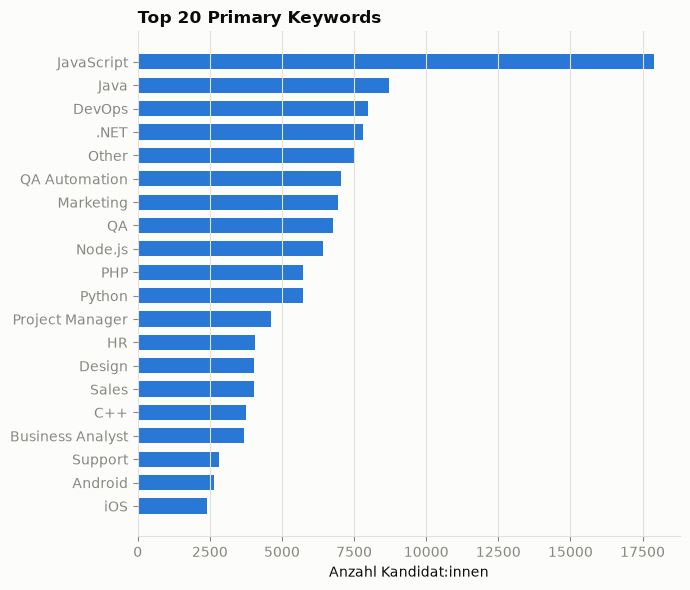

Anzahl unterschiedlicher Keywords: 45


In [27]:
top_keywords = jobs["Primary Keyword"].value_counts().head(20)

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top_keywords.index[::-1], top_keywords.values[::-1], color=BLUE, height=0.65)
ax.set_xlabel("Anzahl Kandidat:innen")
ax.set_title("Top 20 Primary Keywords", loc="left", color=INK, fontweight="bold")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print(f"Anzahl unterschiedlicher Keywords: {jobs['Primary Keyword'].nunique()}")

## 5. Berufserfahrung (Required Experience Years)

Wie viele Jahre Berufserfahrung setzen die Unternehmen voraus? Dieser Abgleich ist wichtig, da die Kandidat:innen im CV-Datensatz einen Median von 3 Jahren mitbringen. Wir prüfen hier, ob Angebot und Nachfrage bei der Seniorität auf dem Markt übereinstimmen.

count    141897.000000
mean          2.700233
std           1.395328
min           0.000000
25%           2.000000
50%           3.000000
75%           3.000000
max           5.000000
Name: Exp Years, dtype: float64


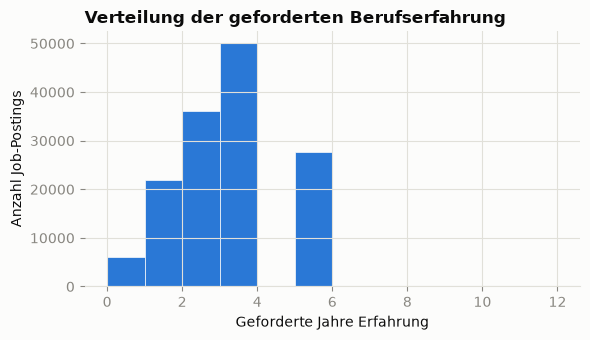

In [28]:
# 'no_exp' zu '0' machen, 'y' entfernen und in numerische Werte (float) umwandeln
jobs["Exp Years"] = jobs["Exp Years"].str.replace("no_exp", "0").str.replace("y", "").astype(float)

# Deskriptive Statistik
print(jobs["Exp Years"].describe())

# Plot
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(jobs["Exp Years"].dropna(), bins=range(0, 13), color=BLUE, edgecolor=SURFACE, linewidth=0.5)
ax.set_xlabel("Geforderte Jahre Erfahrung")
ax.set_ylabel("Anzahl Job-Postings")
ax.set_title("Verteilung der geforderten Berufserfahrung", loc="left", color=INK, fontweight="bold")
plt.tight_layout()
plt.show()

## 6. Englischkenntnisse

Geordnete (ordinale) Kategorie
Der Abgleich zeigt uns, ob die sprachlichen Anforderungen der Unternehmen mit dem tatsächlichen Angebot (meist "upper" bis "intermediate") auf dem Arbeitsmarkt übereinstimmen.

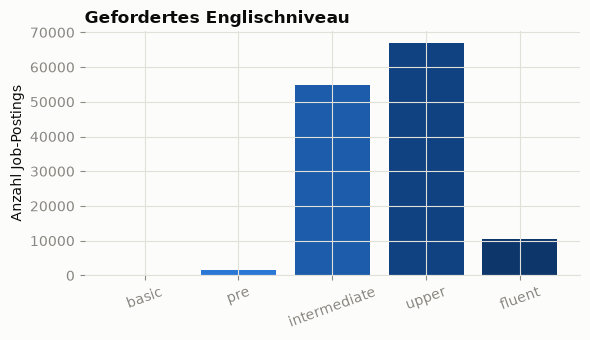

In [29]:
level_order = ["no_english", "basic", "pre", "intermediate", "upper", "fluent"]
level_counts = jobs["English Level"].value_counts().reindex(level_order)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(level_counts.index, level_counts.values, color=BLUE_ORDINAL[:len(level_order)])
ax.set_ylabel("Anzahl Job-Postings")
ax.set_title("Gefordertes Englischniveau", loc="left", color=INK, fontweight="bold")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 7. Text Length of Job Postings

Da unser ESCOX-Parser im nächsten Schritt unstrukturierte Freitexte in standardisierte ESCO-Labels übersetzen muss, ist der semantische Kontext entscheidend. Mit einem Durchschnitt von rund 260 Wörtern pro Long Description liefert der Datensatz eine sehr solide Basis für die Informationsextraktion.

count    141897.000000
mean        260.125690
std         142.608348
min           6.000000
25%         159.000000
50%         234.000000
75%         330.000000
max        2022.000000
Name: Long Description, dtype: float64


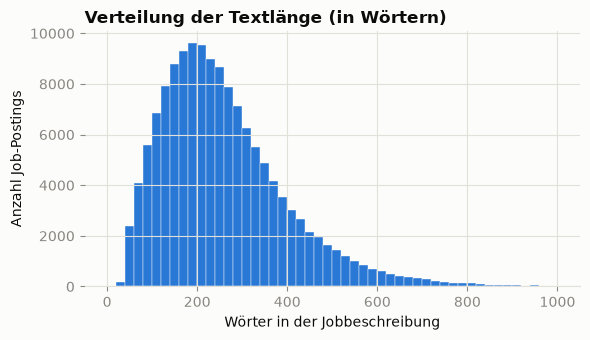

In [31]:
# Wörter in 'Long Description' zählen
desc_len_words = jobs["Long Description"].dropna().str.split().str.len()
print(desc_len_words.describe())

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(desc_len_words.dropna(), bins=50, range=(0, 1000), color=BLUE, edgecolor=SURFACE, linewidth=0.3)
ax.set_xlabel("Wörter in der Jobbeschreibung")
ax.set_ylabel("Anzahl Job-Postings")
ax.set_title("Verteilung der Textlänge (in Wörtern)", loc="left", color=INK, fontweight="bold")
plt.tight_layout()
plt.show()

## 8. Vergleich CVs vs Job Postings

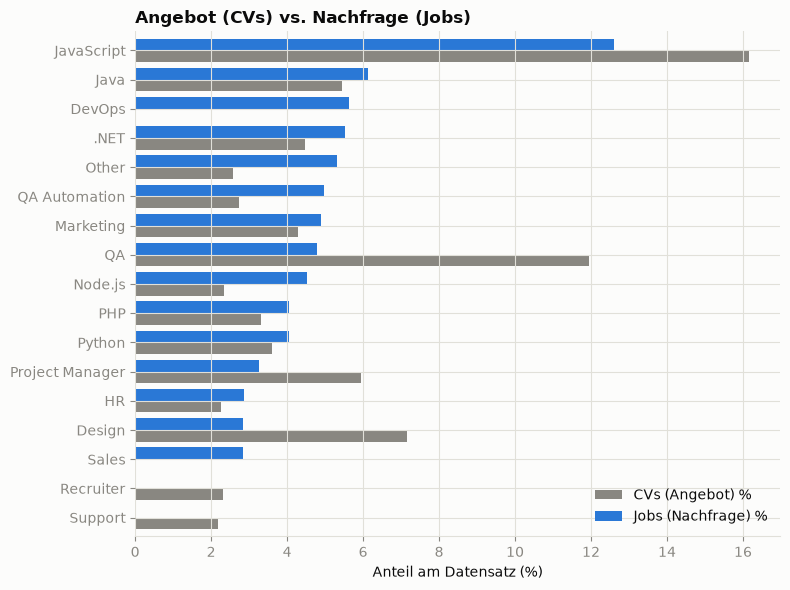

In [32]:
# Top 15 Keywords aus beiden Datensätzen berechnen und als Prozentwerte normieren
cv = pd.read_parquet("../data/raw/djinni/cv_profiles_en.parquet")
cv_kws = cv["Primary Keyword"].value_counts(normalize=True).head(15) * 100
job_kws = jobs["Primary Keyword"].value_counts(normalize=True).head(15) * 100

# Direkter Vergleich
mismatch_df = pd.DataFrame({"CVs (Angebot) %": cv_kws, "Jobs (Nachfrage) %": job_kws}).fillna(0)
mismatch_df = mismatch_df.sort_values(by="Jobs (Nachfrage) %", ascending=True)

# Plot
mismatch_df.plot(kind="barh", figsize=(8, 6), color=[MUTED, BLUE], width=0.8)
plt.title("Angebot (CVs) vs. Nachfrage (Jobs)", loc="left", color=INK, fontweight="bold")
plt.xlabel("Anteil am Datensatz (%)")
plt.ylabel("")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

Dieser direkte Vergleich der Top-Keywords aus Lebensläufen und Stellenanzeigen belegt empirisch die Notwendigkeit unseres geplanten MMR Re-Rankings (Maximal Marginal Relevance). Der Markt zeigt ein massives Überangebot an bestimmten Profilen. Ohne ein ausgleichendes Re-Ranking-Verfahren zur aktiven Förderung der Skill-Diversität würden Recruiter:innen bei der Vorauswahl mit redundanten Standardprofilen überflutet werden, wodurch "Hidden Talents" unsichtbar blieben.

## 9. Bias Proxies in den Freitexten

Die Suche nach potenziell ausschließenden Begriffen (wie "young" oder "guy") zeigt, dass ein relevanter Teil der Stellenanzeigen sprachliche Stellvertretermerkmale (Proxies) enthält.

In [34]:
# Liste von typischen Bias-Begriffen
bias_terms = ["young", "dynamic", "digital native", "ninja", "rockstar", "he/she", "guy"]

jobs["has_bias_proxy"] = jobs["Long Description"].str.lower().str.contains("|".join(bias_terms), na=False)

proxy_count = jobs["has_bias_proxy"].sum()
proxy_pct = (proxy_count / len(jobs)) * 100

print(f"Postings mit potenziellen Bias-Begriffen: {proxy_count:,} ({proxy_pct:.1f}%)")

term_counts = {term: jobs["Long Description"].str.lower().str.contains(term, na=False).sum() for term in bias_terms}
print("Treffer pro Begriff:", term_counts)

Postings mit potenziellen Bias-Begriffen: 16,964 (12.0%)
Treffer pro Begriff: {'young': 3792, 'dynamic': 12732, 'digital native': 19, 'ninja': 144, 'rockstar': 175, 'he/she': 327, 'guy': 506}


## 10. Quereinsteiger Check

In [38]:
# Bildungs Keywords, die auf formale Bildung hinweisen
edu_terms = [r"\bbachelor\b", r"\bmaster\b", r"\bphd\b", r"\bdegree\b", r"\buniversity\b", r"\bacademic\b"]
regex_pattern = "|".join(edu_terms)

# Suche
jobs["requires_formal_edu"] = jobs["Long Description"].str.contains(regex_pattern, case=False, na=False, regex=True)
edu_count = jobs["requires_formal_edu"].sum()
edu_pct = (edu_count / len(jobs)) * 100

print(f"Postings, die explizit formale Bildung erwähnen: {edu_count:,} ({edu_pct:.1f}%)")

print("\nBeispiel-Kontext aus den Postings:")
sample_edu_texts = jobs[jobs["requires_formal_edu"]]["Long Description"].dropna().sample(3, random_state=42)

# Ausgabe der Snippets
for text in sample_edu_texts:
    match = re.search(regex_pattern, text, flags=re.IGNORECASE)
    if match:
        start = max(0, match.start() - 60)
        end = min(len(text), match.end() + 60)
        snippet = text[start:end].replace('\n', ' ')
        print(f"- ...{snippet}...")

Postings, die explizit formale Bildung erwähnen: 21,773 (15.3%)

Beispiel-Kontext aus den Postings:
 - 6 + years o...ter's degree in Computer Engineering;
 - Bachelor’s degree in marketing, advertising, communications or equiv...
 Bachelor’s Degree, Diploma OR Equivalent and 2+ years of experience ...


Dass 15 % der Anzeigen formale Bildungsabschlüsse fordern, belegt das Risiko von 'Degree Inflation' auf dem Arbeitsmarkt. Für MeritMe ist dies das zentrale Testszenario: Unser ESCO-basiertes Matching muss beweisen, dass es fähig ist, diese formalen Proxies zu ignorieren und stattdessen die tatsächlichen Kompetenzen von Quereinsteiger:innen (Counterfactual Twins) fair zu bewerten.

## 11. Duplikate und Datenqualität

In [39]:
duplicates = jobs.duplicated(subset=["Long Description"]).sum()
dup_pct = (duplicates / len(jobs)) * 100
print(f"Exakte Text-Duplikate in 'Long Description': {duplicates:,} ({dup_pct:.1f}%)")

# Kurze Texte (weniger als 10 Wörter) identifizieren
short_texts = (desc_len_words < 10).sum()
short_pct = (short_texts / len(jobs)) * 100
print(f"Stellenanzeigen mit weniger als 10 Wörtern: {short_texts:,} ({short_pct:.1f}%)")

Exakte Text-Duplikate in 'Long Description': 0 (0.0%)
Stellenanzeigen mit weniger als 10 Wörtern: 2 (0.0%)


## 12. Zusammenfassung – erste Beobachtungen

**1. Datenqualität**
- Guter Zustand: Es gibt keine fehlenden Werte in der `Long Description` und 0 % Duplikate 
- Die durchschnittliche Textlänge von ca. 260 Wörtern ist ideal für den ESCOX-Parser

**2. Architektur-Validierung (MMR & ESCO)**
- Wir haben ein Angebotsüberschuss der Kandidat:innen (bei Standardprofilen wie JavaScript und QA) -> Bestätigt dass für Skilldiversität MMR notwendig ist
- 12% Bias Proxies belegen, dass die unbereinigten Freitexte strukturellen Bias enthalten -> ESCO Ansatz notwendig

**3. Fairness-Testing**
Dass 15,3 % der Jobs explizit formale Abschlüsse fordern, liefert uns eine Baseline für die Modellevaluation. Wir können messen, ob unser System Quereinsteiger-Profile fair bewertet.

**Action Items für den nächsten Sprint:**
- Die 2 Stellenanzeigen mit weniger als 10 Wörtern (`short_texts`) herausfiltern.
- Den bereinigten Datensatz an die ESCOX-Pipeline übergeben, um die unstrukturierten Freitexte in standardisierte Skill-Labels zu übersetzen.